In [2]:
import numpy as np
import matplotlib.pyplot as plt

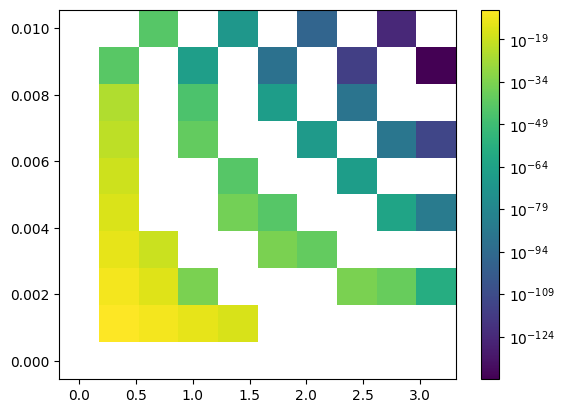

In [3]:
from matplotlib.colors import LogNorm


N = 10
T = np.pi

n = np.arange(1, N + 1)

s_min, s_max = 0, np.pi
t_min, t_max = 0, 0.01
s = np.linspace(s_min, s_max, N)
t = np.linspace(t_min, t_max, N)
s_mesh, t_mesh = np.meshgrid(s, t)

# x_n = np.sqrt(2/np.pi) * np.sin(n * s_mesh)
# y_n = np.sqrt(2/np.pi) * np.sin(n * t_mesh)


def x_n(s, n):
    return np.sqrt(2/np.pi) * np.sin(n[:, None] * s[None, :])

def y_n(t, n):
    return np.sqrt(2/np.pi) * np.sin(n[:, None] * t[None, :])

def mu_n(n, T):
    return np.exp(-T * n[:, None] * n[None, :])

def A(s, t, n, T):
    return x_n(s, n) * y_n(t, n).T * mu_n(n, T)



# x_vec = x_n(s, n)
# # plt.plot(x_vec)
# plt.imshow(mu_n(n, T))
im = plt.pcolormesh(s, t, A(s, t, n, T), norm=LogNorm())
plt.colorbar(im)
# def y_n(t, n):
#     return np.sqrt(2/np.pi) * np.sin(n * t)

# def mu_n(n, T):
#     return np.exp(-T * n**2)

# def A(s, t, n, T):
#     return x_n(s, n) * y_n(t, n) * mu_n(n, T)

# A = 2 / np.pi * np.sin(n * s_mesh) * np.sin(n * t_mesh) * np.exp(-T * n**2)
# plt.imshow(A)

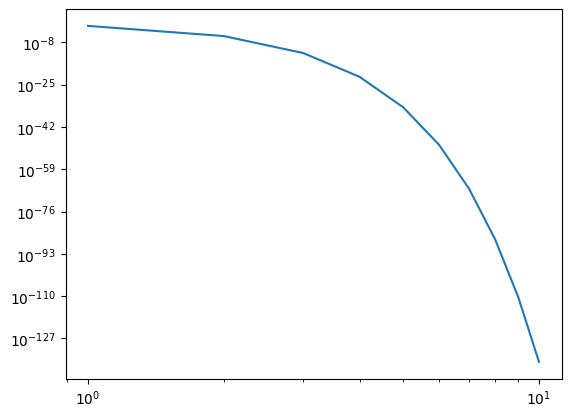

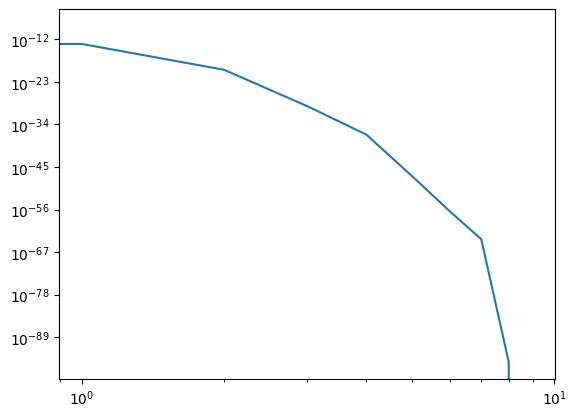

In [4]:
U, Sigma, V = np.linalg.svd(A(s, t, n, T))
Sigma

def singular_functions(n):
    return np.exp(-T * n**2)

plt.figure()
plt.loglog(n, singular_functions(n))

plt.figure()
plt.loglog(Sigma)

In [5]:
def HF(x0, T):
    N = len(x0) - 1
    k = np.fft.fftshift(np.arange(-N, N))  # Wave numbers

    # Odd extension to enforce sine series
    x = x0[1:-1]
    x_ext = np.concatenate(([0], x, [0], -x[::-1]))

    # FFT and time evolution
    x_hat = np.fft.fft(x_ext)
    x_hatT = x_hat * np.exp(-k**2 * T)
    xend = np.fft.ifft(x_hatT)

    return np.real(xend[:N+1])



<>:98: SyntaxWarning: invalid escape sequence '\s'
<>:98: SyntaxWarning: invalid escape sequence '\s'
C:\Users\jeppe\AppData\Local\Temp\ipykernel_6148\1281341009.py:98: SyntaxWarning: invalid escape sequence '\s'
  ax.plot(s, v_n_scaled, 'b-', linewidth=2, label=f'Numerical $v_{n} / \sqrt{{h}}$')


Constructed matrix A of size (50, 50)
SVD computation complete.


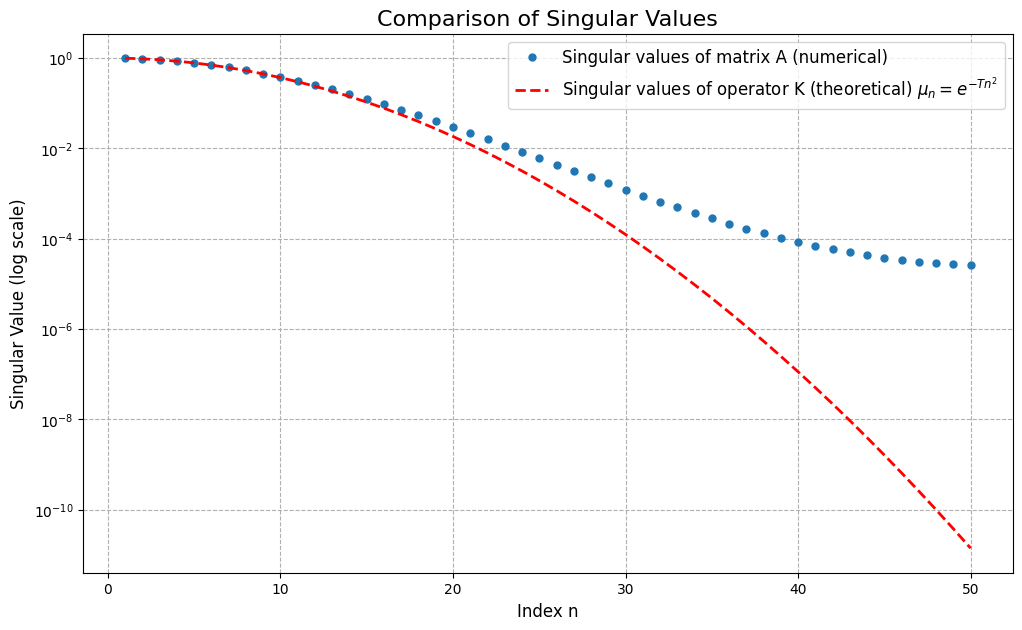

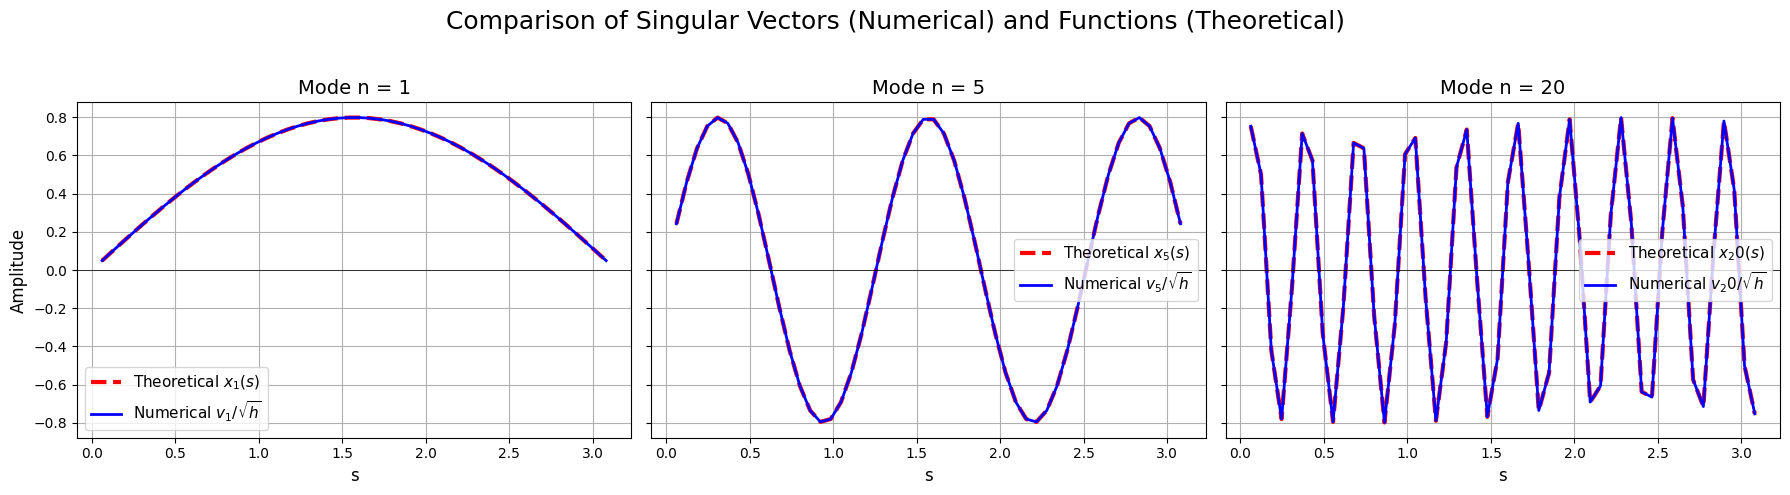


### Explanation for Why the Singular Values for A Level Off

1.  **Continuous vs. Discrete Operator:** The singular values of the continuous heat operator, `μ_n = exp(-T*n^2)`, decay exceptionally fast towards zero without leveling off. The matrix `A` is a numerical discretization of this continuous operator, and its properties are limited by the nature of the discretization.

2.  **Finite Difference Approximation:** We constructed `A` using a finite difference method, where `A = expm(T * L)`, and `L` is the matrix representing the second spatial derivative. The accuracy of this approximation depends on the frequency (or mode number `n`) of the function it acts upon. It is highly accurate for low-frequency (smooth) functions but loses accuracy for high-frequency functions.

3.  **Eigenvalues of the Discrete Laplacian:** The singular values of our symmetric matrix `A` are determined by the eigenvalues of the discrete Laplacian `L`. The n-th eigenvalue of `L` is given by:
    `λ_n(L) = 

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

def construct_heat_matrix(m, T, domain_length=np.pi):
    """
    Constructs the discrete forward operator matrix A for the 1D heat equation
    u_t = u_ss on [0, L] with zero Dirichlet boundary conditions.

    Args:
        m (int): Number of interior spatial grid points.
        T (float): Final time.
        domain_length (float): The length L of the spatial domain.

    Returns:
        np.ndarray: The m x m matrix A.
        np.ndarray: The array of spatial grid points s.
        float: The grid spacing h.
    """
    # Spatial discretization
    h = domain_length / (m + 1)
    s = np.linspace(h, domain_length - h, m)

    # Construct the finite difference matrix for the second derivative (Laplacian)
    main_diag = -2 * np.ones(m)
    off_diag = np.ones(m - 1)
    L_matrix = (1 / h**2) * (np.diag(main_diag) + np.diag(off_diag, k=1) + np.diag(off_diag, k=-1))

    # The forward operator A is the matrix exponential of T * L
    A = expm(T * L_matrix)

    return A, s, h

def solve_and_compare_svd():
    """
    Main function to perform SVD, compare results, and provide explanation.
    """
    # --- 1. Setup Parameters and Compute SVD for Matrix A ---

    m = 50          # Number of interior spatial points
    T = 0.01        # Final time
    L_domain = np.pi # Length of the domain [0, pi]

    # Construct the matrix A and get grid info
    A, s, h = construct_heat_matrix(m, T, L_domain)

    # Compute the SVD of A: A = U * Sigma * V^T
    U, s_vals_A, Vt = np.linalg.svd(A)
    V = Vt.T

    print(f"Constructed matrix A of size {A.shape}")
    print("SVD computation complete.")

    # --- 2. Compare Singular Values and Vectors ---

    # --- Singular Value Comparison ---
    n_indices = np.arange(1, m + 1)

    # Theoretical singular values for the continuous operator K on [0, pi]
    # For a general domain [0, L], mu_n = exp(-T * (n*pi/L)^2)
    # Since L=pi, this simplifies to exp(-T * n^2)
    mu_n_K = np.exp(-T * n_indices**2)

    plt.figure(figsize=(12, 7))
    plt.semilogy(n_indices, s_vals_A, 'o', markersize=5, label='Singular values of matrix A (numerical)')
    plt.semilogy(n_indices, mu_n_K, 'r--', linewidth=2, label=r'Singular values of operator K (theoretical) $\mu_n = e^{-Tn^2}$')
    plt.title('Comparison of Singular Values', fontsize=16)
    plt.xlabel('Index n', fontsize=12)
    plt.ylabel('Singular Value (log scale)', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, which="both", ls="--")
    plt.show()

    # --- Singular Vector/Function Comparison ---
    modes_to_compare = [1, 5, 20]

    fig, axes = plt.subplots(1, len(modes_to_compare), figsize=(18, 5), sharey=True)

    for i, n in enumerate(modes_to_compare):
        ax = axes[i]

        # Numerical singular vector from SVD of A (column n-1 of V)
        v_n = V[:, n - 1]

        # Theoretical singular function x_n(s) = sqrt(2/L) * sin(n*pi*s/L)
        x_n_continuous_sampled = np.sqrt(2 / L_domain) * np.sin(n * np.pi * s / L_domain)

        # The SVD vectors v_n are normalized in the vector L2 norm (sum of squares is 1).
        # The continuous functions x_n are normalized in the L2 function space (integral of square is 1).
        # To compare them, we scale v_n by 1/sqrt(h) to approximate the function values.
        v_n_scaled = v_n / np.sqrt(h)

        # Correct for potential sign flip in SVD output for consistent visualization
        if np.dot(v_n_scaled, x_n_continuous_sampled) < 0:
            v_n_scaled = -v_n_scaled

        ax.plot(s, x_n_continuous_sampled, 'r--', linewidth=3, label=f'Theoretical $x_{n}(s)$')
        ax.plot(s, v_n_scaled, 'b-', linewidth=2, label=f'Numerical $v_{n} / \sqrt{{h}}$')
        ax.set_title(f'Mode n = {n}', fontsize=14)
        ax.set_xlabel('s', fontsize=12)
        if i == 0:
            ax.set_ylabel('Amplitude', fontsize=12)
        ax.legend(fontsize=11)
        ax.grid(True)
        ax.axhline(0, color='black', linewidth=0.5)

    fig.suptitle('Comparison of Singular Vectors (Numerical) and Functions (Theoretical)', fontsize=18)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

    # --- 3. Explanation for Leveling Off ---
    explanation = """
### Explanation for Why the Singular Values for A Level Off

1.  **Continuous vs. Discrete Operator:** The singular values of the continuous heat operator, `μ_n = exp(-T*n^2)`, decay exceptionally fast towards zero without leveling off. The matrix `A` is a numerical discretization of this continuous operator, and its properties are limited by the nature of the discretization.

2.  **Finite Difference Approximation:** We constructed `A` using a finite difference method, where `A = expm(T * L)`, and `L` is the matrix representing the second spatial derivative. The accuracy of this approximation depends on the frequency (or mode number `n`) of the function it acts upon. It is highly accurate for low-frequency (smooth) functions but loses accuracy for high-frequency functions.

3.  **Eigenvalues of the Discrete Laplacian:** The singular values of our symmetric matrix `A` are determined by the eigenvalues of the discrete Laplacian `L`. The n-th eigenvalue of `L` is given by:
    `λ_n(L) = - (4/h^2) * sin^2(n*π / (2*(m+1)))`
    where `h` is the grid spacing and `m` is the number of grid points.

4.  **Behavior at Low and High Frequencies:**
    *   **For small `n` (low frequencies):** The `sin(x) ≈ x` approximation is valid, which leads to `λ_n(L) ≈ -n^2`. Consequently, the singular values of `A`, `σ_n = exp(T*λ_n(L))`, closely match the theoretical continuous values `μ_n = exp(-T*n^2)`. Our plot clearly shows this excellent agreement for the first several singular values.
    *   **For large `n` (high frequencies, n approaching m):** The term `sin^2(...)` approaches `sin^2(π/2) = 1`. This means the eigenvalues of `L` stop decaying quadratically and instead approach a constant floor:
        `λ_n(L) → -4/h^2` as `n → m`.

5.  **Conclusion on Leveling Off:** Because the eigenvalues of `L` level off, the singular values of `A` also level off at a non-zero floor:
    `σ_n → exp(-4*T/h^2)` as `n → m`.
    This "leveling off" is an artifact of the discretization. The finite difference grid cannot accurately represent very high-frequency sine waves, and the numerical operator `A` damps all these high frequencies by a similar, maximal amount determined by the grid spacing `h` and the time `T`.
"""
    print(explanation)

if __name__ == '__main__':
    solve_and_compare_svd()

# Exercise 3

See paper

# Exercise 4

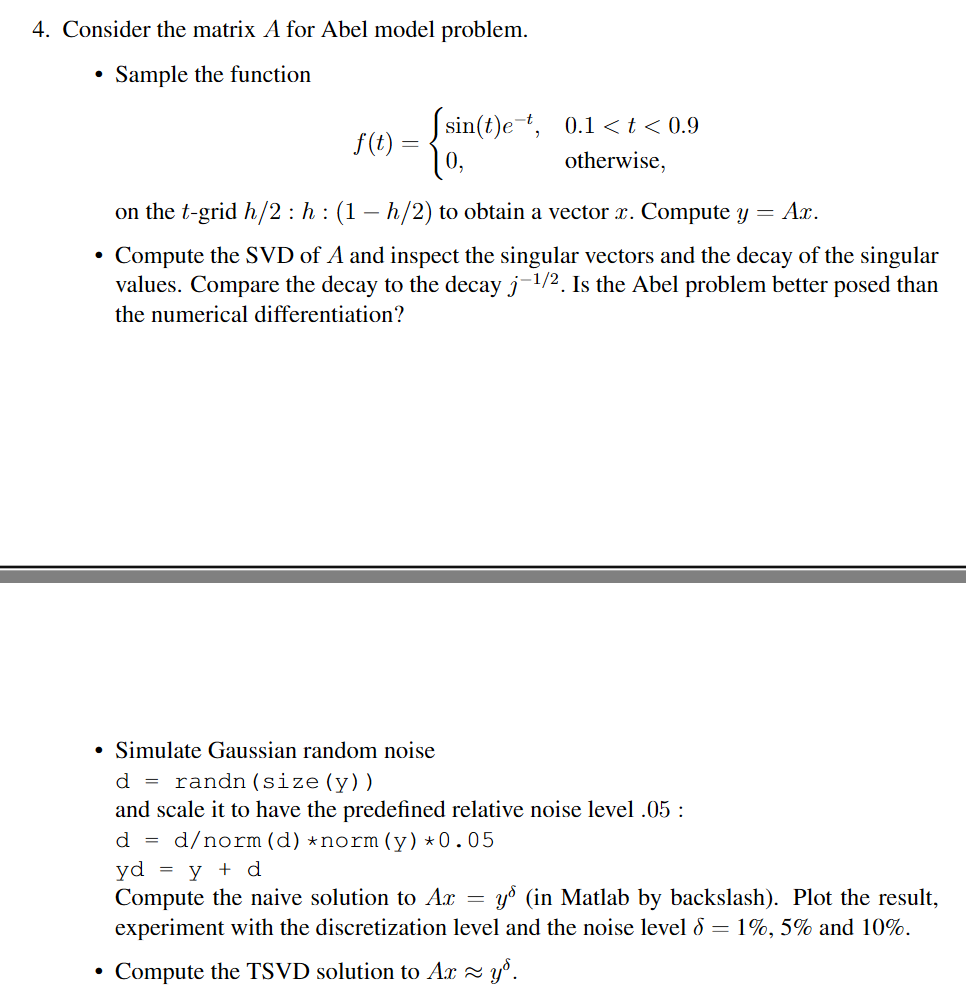

(32,)

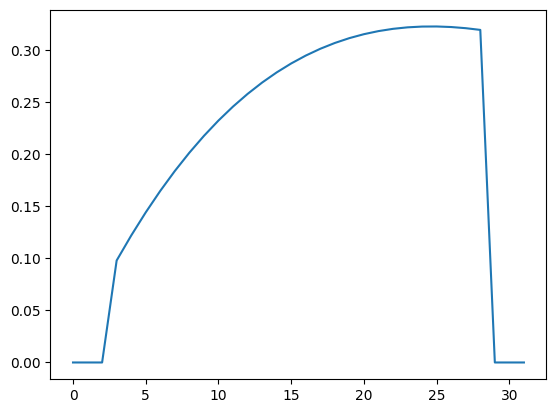

In [18]:
def f(t):
    return np.where((0.1 < t) & (t < 0.9), np.sin(t) * np.exp(-t), 0.0)

N = 32  # Discretization points
h = 1 / N  # Step size
t_grid = np.linspace(h / 2, 1 - h / 2, N)
s_grid = t_grid + h/2
s_grid = s_grid.reshape(-1, 1)
x = f(t_grid)
plt.plot(x)

t_grid.shape

(32, 32)


np.float64(1.0000000000000002)

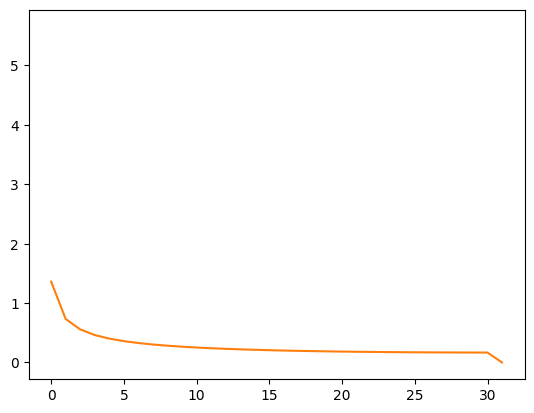

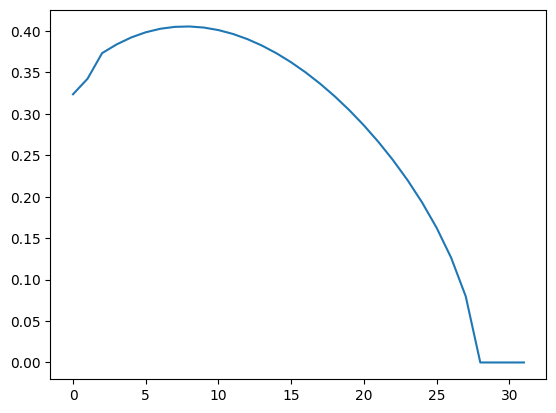

In [ ]:
# Abel Operator
def A_abel(s, t, N, h):
    s_matrix = np.tile(s, (1, N))
    t_matrix = np.tile(t, (N, 1))

    A = np.zeros((len(s), len(t)))
    mask = s_matrix < t_matrix
    print(mask.shape)
    A[mask] = h / np.sqrt(np.abs(s_matrix[mask] - t_matrix[mask]))
    return A

A = A_abel(s_grid, t_grid, N, h)
y = A @ x

U, Sigma, V = np.linalg.svd(A)
plt.figure()
plt.plot(np.linalg.norm(U))
plt.plot(Sigma)

plt.figure()
plt.plot(y)
